# Ferro Vision - Notebook 1: Remaining Useful Life (RUL) Regression

**Goal:** predict how many operating cycles a turbofan engine has left before failure.

| Model | Input | Output |
|---|---|---|
| **ANN** (baseline) | one cycle's sensor snapshot | one RUL value |
| **RNN** | window of 30 cycles | RUL at every step (many-to-many) |
| **LSTM** | window of 30 cycles | RUL at every step (many-to-many) |

**Framework:** TensorFlow / Keras (used consistently across the whole project).

**Before you run:** put the dataset CSV at `data/turbofan.csv` (or change `CSV_PATH` below). Expected columns:
`engine_id, cycle, op_setting_1..3, sensor_1..21, RUL`.

**Notebook outline**
1. Setup and configuration
2. Data loading
3. Data cleaning
4. Exploratory data analysis
5. Train / validation / test split (by engine)
6. Scaling
7. ANN baseline (static snapshot)
8. Sequence windowing
9. RNN and LSTM (sequence-to-sequence)
10. Evaluation and comparison
11. Discussion
12. Saving models and artifacts

## 1. Setup and configuration

In [1]:
!pip install joblib


[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
!pip install tensorflow numpy pandas scikit-learn joblib pillow matplotlib seaborn plotly streamlit jupyter ipykernel


[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os, json, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

# ---------------- configuration ----------------
SEED     = 42
CSV_PATH = "../data/turbofan.csv"   # <- change if your file is elsewhere
WINDOW   = 30                    # cycles per sequence window
STRIDE   = 1                     # step between consecutive windows
EPOCHS   = 100                   # upper bound; EarlyStopping stops sooner
BATCH    = 256
RUL_CAP  = None                  # e.g. 125 clips RUL (often improves scores, but changes the benchmark)

ID_COL, TIME_COL, TARGET = "engine_id", "cycle", "rul"

random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
os.makedirs("../models", exist_ok=True)
os.makedirs("../artifacts", exist_ok=True)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.22.0-rc0


## 2. Data loading

In [4]:
df = pd.read_csv(CSV_PATH)
df.columns = [c.strip().lower() for c in df.columns]   # normalise column names

missing_cols = [c for c in (ID_COL, TIME_COL) if c not in df.columns]
assert not missing_cols, f"Missing required columns: {missing_cols}. Found: {list(df.columns)}"

# If the file has no RUL column, derive it: cycles remaining until each engine's last cycle
if TARGET not in df.columns:
    df[TARGET] = df.groupby(ID_COL)[TIME_COL].transform("max") - df[TIME_COL]
    print("RUL column not found -> derived from max cycle per engine.")

print("Shape:", df.shape)
df.head()

Shape: (61249, 27)


,engine_id,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,rul
0,1,1,42.0049,0.8400,100.0,445.00,549.68,1343.43,1112.93,3.91,5.70,137.36,2211.86,8311.32,1.01,41.69,129.78,2387.99,8074.83,9.3335,0.02,330,2212,100.00,10.62,6.3670,320
1,1,2,20.0020,0.7002,100.0,491.19,606.07,1477.61,1237.50,9.35,13.61,332.10,2323.66,8713.60,1.07,43.94,312.59,2387.73,8046.13,9.1913,0.02,361,2324,100.00,24.37,14.6552,319
2,1,3,42.0038,0.8409,100.0,445.00,548.95,1343.12,1117.05,3.91,5.69,138.18,2211.92,8306.69,1.01,41.66,129.62,2387.97,8066.62,9.4007,0.02,329,2212,100.00,10.48,6.4213,318
3,1,4,42.0000,0.8400,100.0,445.00,548.70,1341.24,1118.03,3.91,5.70,137.98,2211.88,8312.35,1.02,41.68,129.80,2388.02,8076.05,9.3369,0.02,328,2212,100.00,10.54,6.4176,317
4,1,5,25.0063,0.6207,60.0,462.54,536.10,1255.23,1033.59,7.05,9.00,174.82,1915.22,7994.94,0.93,36.48,164.11,2028.08,7865.80,10.8366,0.02,305,1915,84.93,14.03,8.6754,316


## 3. Data cleaning

In [5]:
df.info()
print("\nColumns with nulls:")
nulls = df.isnull().sum()
print(nulls[nulls > 0] if (nulls > 0).any() else "None")

<class 'pandas.DataFrame'>
RangeIndex: 61249 entries, 0 to 61248
Data columns (total 27 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   engine_id     61249 non-null  int64  
 1   cycle         61249 non-null  int64  
 2   op_setting_1  61249 non-null  float64
 3   op_setting_2  61249 non-null  float64
 4   op_setting_3  61249 non-null  float64
 5   sensor_1      61249 non-null  float64
 6   sensor_2      61249 non-null  float64
 7   sensor_3      61249 non-null  float64
 8   sensor_4      61249 non-null  float64
 9   sensor_5      61249 non-null  float64
 10  sensor_6      61249 non-null  float64
 11  sensor_7      61249 non-null  float64
 12  sensor_8      61249 non-null  float64
 13  sensor_9      61249 non-null  float64
 14  sensor_10     61249 non-null  float64
 15  sensor_11     61249 non-null  float64
 16  sensor_12     61249 non-null  float64
 17  sensor_13     61249 non-null  float64
 18  sensor_14     61249 non-null  float64

In [6]:
# Sort so every engine's history is in time order
df = df.sort_values([ID_COL, TIME_COL]).reset_index(drop=True)

feature_candidates = [c for c in df.columns if c.startswith("op_setting") or c.startswith("sensor")]
print(f"{len(feature_candidates)} candidate features")

# Impute missing readings *within each engine* (forward then backward fill), never across engines
if df[feature_candidates].isnull().any().any():
    df[feature_candidates] = df.groupby(ID_COL)[feature_candidates].transform(lambda s: s.ffill().bfill())

before = len(df)
df = df.dropna(subset=feature_candidates + [TARGET])
print("Rows dropped for remaining NaNs:", before - len(df))

# Duplicates
n_dup_full = df.duplicated().sum()
n_dup_key  = df.duplicated(subset=[ID_COL, TIME_COL]).sum()
print("Fully duplicated rows:", n_dup_full, "| duplicate (engine, cycle) pairs:", n_dup_key)
df = df.drop_duplicates(subset=[ID_COL, TIME_COL]).reset_index(drop=True)

24 candidate features
Rows dropped for remaining NaNs: 0
Fully duplicated rows: 0 | duplicate (engine, cycle) pairs: 0


In [7]:
# Validate sequencing: every engine should start at cycle 1 and increase by exactly 1
bad_engines = []
for eid, g in df.groupby(ID_COL):
    steps_ok = (g[TIME_COL].diff().dropna() == 1).all()
    starts_ok = g[TIME_COL].iloc[0] == 1
    if not (steps_ok and starts_ok):
        bad_engines.append(eid)

print("Engines:", df[ID_COL].nunique())
print("Engines with gaps / non-1 start:", len(bad_engines), bad_engines[:10])
# If this list is non-empty, inspect those engines before continuing - gaps break the windowing logic.

Engines: 249
Engines with gaps / non-1 start: 0 []


In [8]:
# Drop constant / near-zero-variance features (no degradation signal)
stds = df[feature_candidates].std()
nuniq = df[feature_candidates].nunique()
drop_cols = sorted(set(nuniq[nuniq <= 1].index) | set(stds[stds < 1e-5].index))
print("Dropping:", drop_cols)

feature_cols = [c for c in feature_candidates if c not in drop_cols]
print(f"Kept {len(feature_cols)} features:", feature_cols)

Dropping: []
Kept 24 features: ['op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']


## 4. Exploratory data analysis
Questions: how is RUL distributed, how long do engines live, which sensors move with degradation, and what window length makes sense?

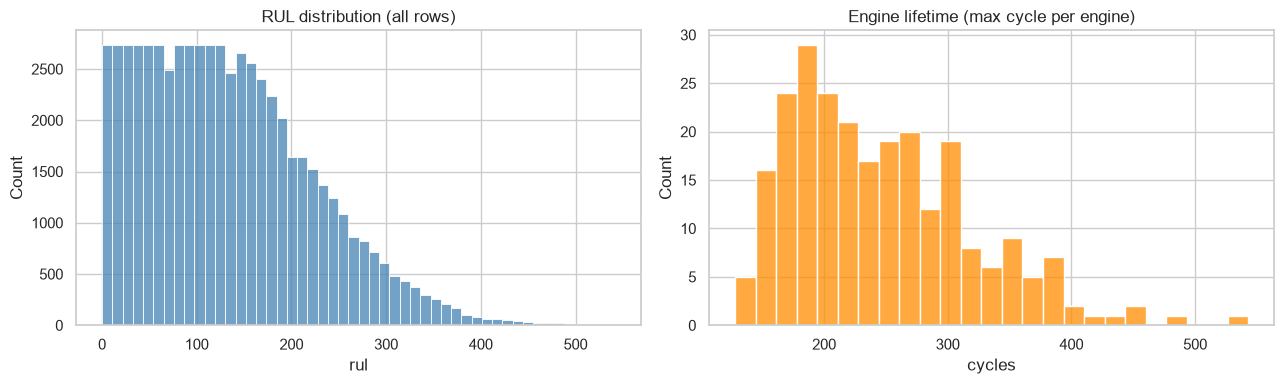

count    249.0
mean     246.0
std       73.1
min      128.0
25%      190.0
50%      234.0
75%      290.0
max      543.0
Name: cycle, dtype: float64

Shortest engine: 128 cycles -> WINDOW=30 is OK


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df[TARGET], bins=50, ax=ax[0], color="steelblue")
ax[0].set_title("RUL distribution (all rows)")

life = df.groupby(ID_COL)[TIME_COL].max()
sns.histplot(life, bins=25, ax=ax[1], color="darkorange")
ax[1].set_title("Engine lifetime (max cycle per engine)")
ax[1].set_xlabel("cycles")
plt.tight_layout(); plt.show()

print(life.describe().round(1))
print(f"\nShortest engine: {life.min()} cycles -> WINDOW={WINDOW} is {'OK' if life.min() >= WINDOW else 'longer than some engines'}")

In [10]:
df[feature_cols].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
op_setting_1,61249.0,24.000,14.781,0.000,10.005,25.001,41.998,42.008
op_setting_2,61249.0,0.571,0.311,0.000,0.251,0.700,0.840,0.842
op_setting_3,61249.0,94.032,14.252,60.000,100.000,100.000,100.000,100.000
sensor_1,61249.0,472.882,26.437,445.000,445.000,462.540,491.190,518.670
sensor_2,61249.0,579.420,37.343,535.480,549.330,555.740,607.070,644.420
sensor_3,61249.0,1417.897,106.168,1242.670,1350.550,1367.680,1497.420,1613.000
sensor_4,61249.0,1201.915,119.328,1024.420,1119.490,1136.920,1302.620,1440.770
sensor_5,61249.0,8.032,3.623,3.910,3.910,7.050,10.520,14.620
sensor_6,61249.0,11.589,5.444,5.670,5.720,9.030,15.480,21.610
sensor_7,61249.0,283.329,146.880,136.170,142.920,194.960,394.280,570.810


sensor_13      -0.401
sensor_11      -0.177
sensor_4       -0.170
sensor_14      -0.168
sensor_17      -0.134
sensor_3       -0.133
sensor_9       -0.117
sensor_2       -0.096
sensor_8       -0.087
sensor_16      -0.063
sensor_10      -0.057
sensor_6       -0.036
sensor_12      -0.022
sensor_7       -0.021
sensor_15      -0.018
sensor_21       0.012
sensor_20       0.011
op_setting_3    0.001
sensor_19       0.001
sensor_5        0.001
op_setting_1   -0.001
op_setting_2   -0.000
sensor_18       0.000
sensor_1       -0.000


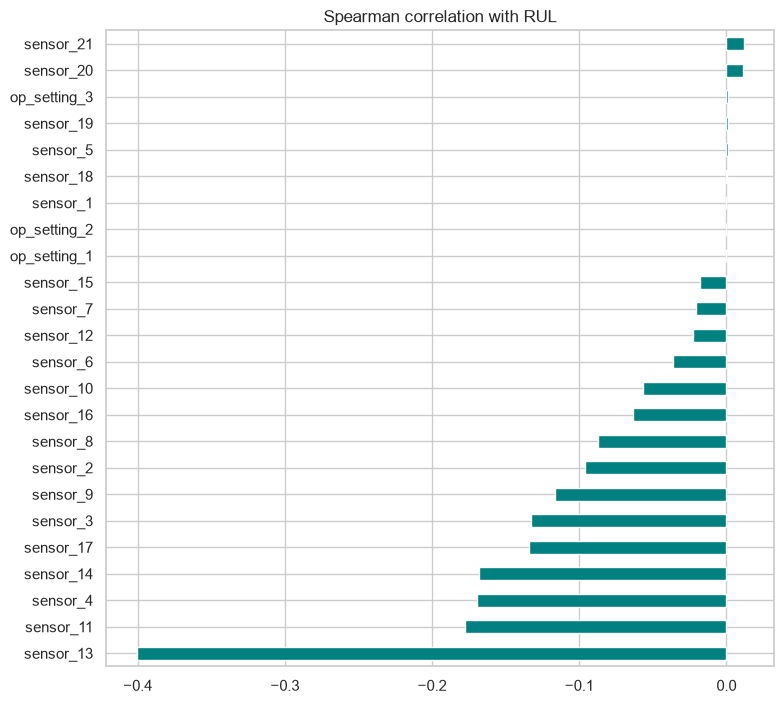

In [11]:
# Correlation of each feature with RUL (Spearman handles monotone degradation trends well)
corr_rul = df[feature_cols + [TARGET]].corr(method="spearman")[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
print(corr_rul.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, max(4, 0.3 * len(corr_rul))))
corr_rul.sort_values().plot.barh(ax=ax, color="teal")
ax.set_title("Spearman correlation with RUL"); plt.tight_layout(); plt.show()

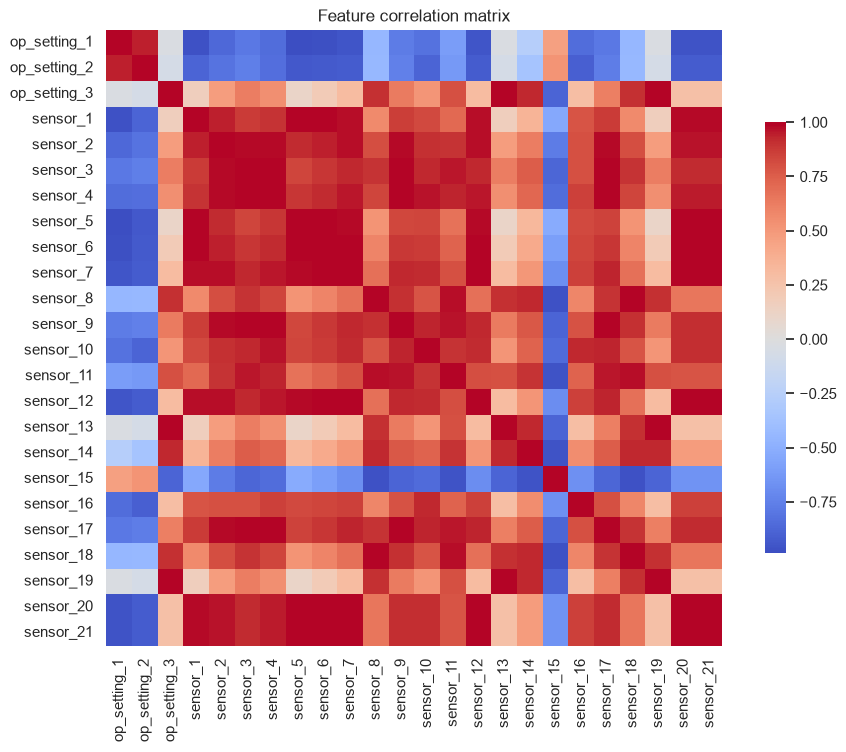

In [12]:
plt.figure(figsize=(11, 8))
sns.heatmap(df[feature_cols].corr(), cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .7})
plt.title("Feature correlation matrix"); plt.show()

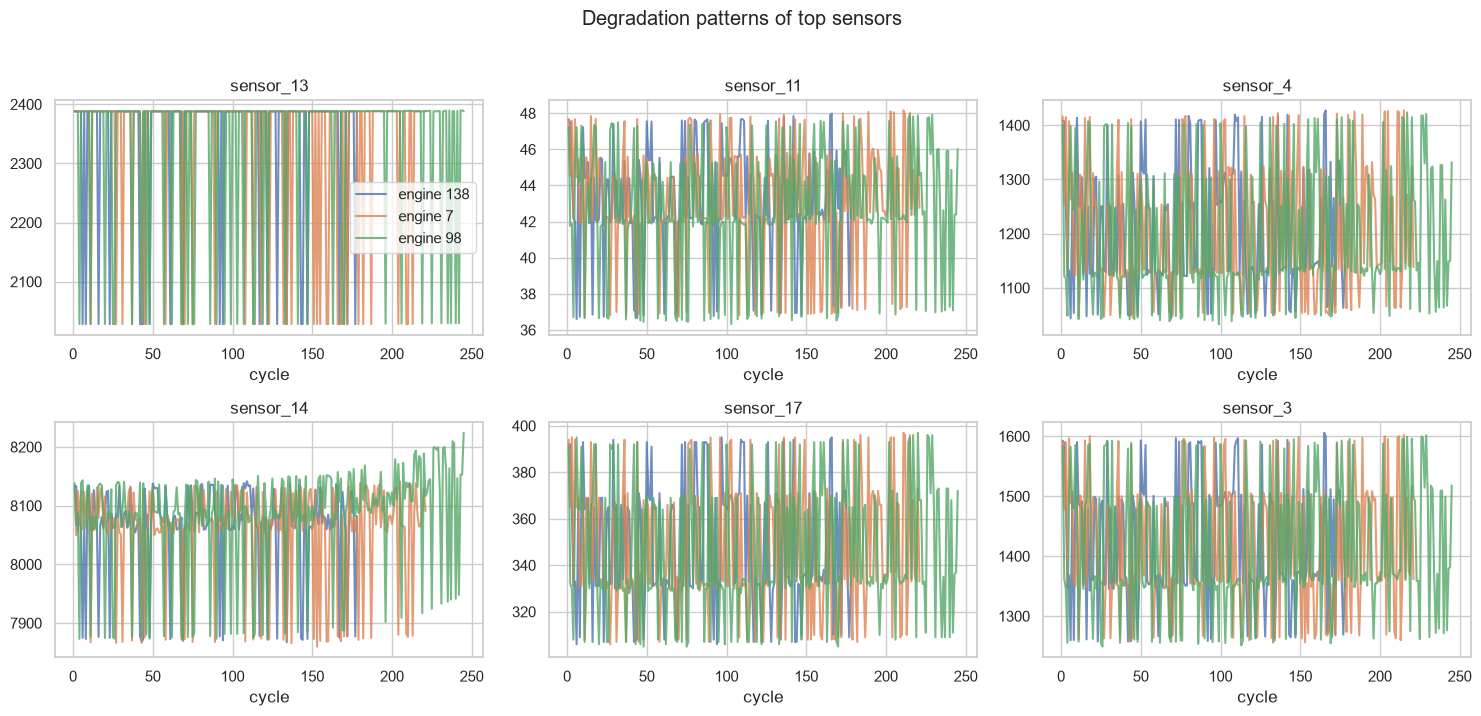

In [13]:
# Sensor trends across cycles for the 6 most RUL-correlated sensors, on 3 random engines
top_sensors = [c for c in corr_rul.index if c.startswith("sensor")][:6]
sample_engines = np.random.RandomState(SEED).choice(df[ID_COL].unique(), 3, replace=False)

fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=False)
for ax, s in zip(axes.ravel(), top_sensors):
    for eid in sample_engines:
        g = df[df[ID_COL] == eid]
        ax.plot(g[TIME_COL], g[s], label=f"engine {eid}", alpha=.8)
    ax.set_title(s); ax.set_xlabel("cycle")
axes[0, 0].legend()
plt.suptitle("Degradation patterns of top sensors", y=1.02); plt.tight_layout(); plt.show()

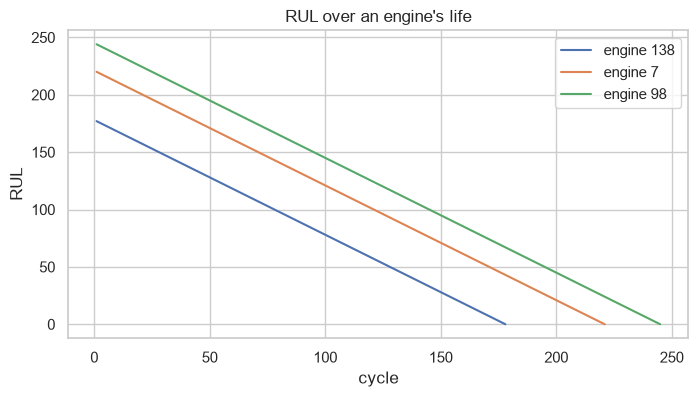

In [14]:
# RUL vs cycle for a few engines (should fall roughly linearly to 0)
plt.figure(figsize=(8, 4))
for eid in sample_engines:
    g = df[df[ID_COL] == eid]
    plt.plot(g[TIME_COL], g[TARGET], label=f"engine {eid}")
plt.xlabel("cycle"); plt.ylabel("RUL"); plt.title("RUL over an engine's life"); plt.legend(); plt.show()

## 5. Train / validation / test split (by engine)

In [15]:
if RUL_CAP is not None:
    df[TARGET] = df[TARGET].clip(upper=RUL_CAP)
    print(f"RUL clipped at {RUL_CAP}")

engine_ids = df[ID_COL].unique().copy()
np.random.RandomState(SEED).shuffle(engine_ids)

n = len(engine_ids)
n_train, n_val = int(0.70 * n), int(0.15 * n)
train_ids = engine_ids[:n_train]
val_ids   = engine_ids[n_train:n_train + n_val]
test_ids  = engine_ids[n_train + n_val:]

assert not (set(train_ids) & set(val_ids)) and not (set(train_ids) & set(test_ids)) and not (set(val_ids) & set(test_ids))

train_df = df[df[ID_COL].isin(train_ids)].copy()
val_df   = df[df[ID_COL].isin(val_ids)].copy()
test_df  = df[df[ID_COL].isin(test_ids)].copy()

print(f"Engines  -> train {len(train_ids)}, val {len(val_ids)}, test {len(test_ids)}")
print(f"Rows     -> train {len(train_df)}, val {len(val_df)}, test {len(test_df)}")

Engines  -> train 174, val 37, test 38
Rows     -> train 42492, val 9179, test 9578


## 6. Scaling

In [16]:
scaler = StandardScaler().fit(train_df[feature_cols])

for d in (train_df, val_df, test_df):
    d[feature_cols] = scaler.transform(d[feature_cols])

joblib.dump(scaler, "../artifacts/scaler.pkl")
with open("../artifacts/config.json", "w") as f:
    json.dump({"feature_cols": feature_cols, "window": WINDOW, "rul_cap": RUL_CAP,
               "id_col": ID_COL, "time_col": TIME_COL, "target": TARGET}, f, indent=2)
print("Saved artifacts/scaler.pkl and artifacts/config.json")
train_df[feature_cols].describe().loc[["mean", "std"]].round(2)

Saved artifacts/scaler.pkl and artifacts/config.json


,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
mean,0.0,-0.0,0.0,0.0,-0.0,0.0,0.0,0.0,0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## Helper: evaluation metrics

In [17]:
def reg_metrics(y_true, y_pred):
    y_true, y_pred = np.ravel(y_true), np.ravel(y_pred)
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse,
            "RMSE": float(np.sqrt(mse)), "R2": r2_score(y_true, y_pred)}

def plot_history(hist, title):
    plt.figure(figsize=(6, 3.5))
    plt.plot(hist.history["loss"], label="train"); plt.plot(hist.history["val_loss"], label="val")
    plt.xlabel("epoch"); plt.ylabel("MSE loss"); plt.title(title); plt.legend(); plt.show()

def make_callbacks():
    return [callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
            callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5)]

## 7. ANN baseline (static per-cycle snapshot)

In [18]:
X_train_s = train_df[feature_cols].values.astype("float32"); y_train_s = train_df[TARGET].values.astype("float32")
X_val_s   = val_df[feature_cols].values.astype("float32");   y_val_s   = val_df[TARGET].values.astype("float32")
X_test_s  = test_df[feature_cols].values.astype("float32");  y_test_s  = test_df[TARGET].values.astype("float32")

def build_ann(n_features):
    m = keras.Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(128, activation="relu"), layers.Dropout(0.2),
        layers.Dense(64, activation="relu"),  layers.Dropout(0.2),
        layers.Dense(32, activation="relu"),
        layers.Dense(1),
    ], name="ann")
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])
    return m

ann = build_ann(len(feature_cols))
ann.summary()

Model: "ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         3,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,569 (53.00 KB)

 Trainable params: 13,569 (53.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
166/166 - 1s - 9ms/step - loss: 12633.9082 - mae: 87.4318 - val_loss: 7424.3652 - val_mae: 70.6349 - learning_rate: 0.0010
Epoch 2/100
166/166 - 0s - 2ms/step - loss: 7669.9473 - mae: 70.0029 - val_loss: 6118.7627 - val_mae: 64.5479 - learning_rate: 0.0010
Epoch 3/100
166/166 - 0s - 2ms/step - loss: 6369.2021 - mae: 63.4744 - val_loss: 4758.8374 - val_mae: 56.5752 - learning_rate: 0.0010
Epoch 4/100
166/166 - 0s - 2ms/step - loss: 5215.4380 - mae: 55.8789 - val_loss: 3655.4595 - val_mae: 46.9793 - learning_rate: 0.0010
Epoch 5/100
166/166 - 0s - 2ms/step - loss: 4541.6318 - mae: 50.4402 - val_loss: 3381.8916 - val_mae: 44.5372 - learning_rate: 0.0010
Epoch 6/100
166/166 - 0s - 2ms/step - loss: 4413.8154 - mae: 49.3676 - val_loss: 3238.9890 - val_mae: 43.2273 - learning_rate: 0.0010
Epoch 7/100
166/166 - 0s - 2ms/step - loss: 4341.5161 - mae: 48.8029 - val_loss: 3231.9377 - val_mae: 43.1560 - learning_rate: 0.0010
Epoch 8/100
166/166 - 0s - 2ms/step - loss: 4266.4258 - mae: 

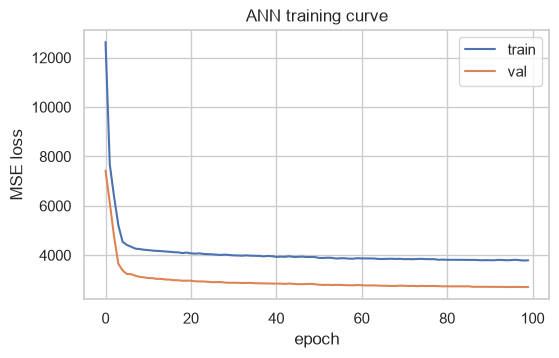

In [19]:
hist_ann = ann.fit(X_train_s, y_train_s, validation_data=(X_val_s, y_val_s),
                   epochs=EPOCHS, batch_size=BATCH, callbacks=make_callbacks(), verbose=2)
plot_history(hist_ann, "ANN training curve")

In [20]:
pred_ann_all = ann.predict(X_test_s, batch_size=1024, verbose=0).ravel()
m_ann_all = reg_metrics(y_test_s, pred_ann_all)
print("ANN on all test cycles:", {k: round(v, 3) for k, v in m_ann_all.items()})

ANN on all test cycles: {'MAE': 42.313, 'MSE': 3565.928, 'RMSE': 59.715, 'R2': 0.58}


## 8. Sequence windowing

In [21]:
def make_windows(d, window=WINDOW, stride=STRIDE):
    Xs, ys, skipped = [], [], 0
    for eid, g in d.groupby(ID_COL, sort=False):
        feats = g[feature_cols].values.astype("float32")
        tgt   = g[TARGET].values.astype("float32")
        if len(g) < window:
            skipped += 1
            continue
        for s in range(0, len(g) - window + 1, stride):
            Xs.append(feats[s:s + window]); ys.append(tgt[s:s + window])
    X = np.stack(Xs); y = np.stack(ys)[..., None]
    return X, y, skipped

X_train_w, y_train_w, sk_tr = make_windows(train_df)
X_val_w,   y_val_w,   sk_va = make_windows(val_df)
X_test_w,  y_test_w,  sk_te = make_windows(test_df)

print("Train windows:", X_train_w.shape, y_train_w.shape, "| engines skipped:", sk_tr)
print("Val   windows:", X_val_w.shape,   y_val_w.shape,   "| engines skipped:", sk_va)
print("Test  windows:", X_test_w.shape,  y_test_w.shape,  "| engines skipped:", sk_te)

Train windows: (37446, 30, 24) (37446, 30, 1) | engines skipped: 0
Val   windows: (8106, 30, 24) (8106, 30, 1) | engines skipped: 0
Test  windows: (8476, 30, 24) (8476, 30, 1) | engines skipped: 0


## 9. RNN and LSTM (many-to-many)

In [22]:
def build_seq_model(cell, window, n_features, units=64, name="seq"):
    m = keras.Sequential([
        layers.Input(shape=(window, n_features)),
        cell(units, return_sequences=True),
        layers.Dropout(0.2),
        cell(32, return_sequences=True),
        layers.TimeDistributed(layers.Dense(32, activation="relu")),
        layers.TimeDistributed(layers.Dense(1)),
    ], name=name)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])
    return m

rnn  = build_seq_model(layers.SimpleRNN, WINDOW, len(feature_cols), name="rnn")
lstm = build_seq_model(layers.LSTM,      WINDOW, len(feature_cols), name="lstm")
lstm.summary()

Model: "lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        22,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 30, 32)         │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_2              │ (None, 30, 32)         │         1,056 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_3              │ (None, 30, 1)          │            33 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 36,289 (141.75 KB)

 Trainable params: 36,289 (141.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
147/147 - 9s - 59ms/step - loss: 20599.2363 - mae: 116.3032 - val_loss: 13944.2158 - val_mae: 92.3711 - learning_rate: 0.0010
Epoch 2/100
147/147 - 3s - 22ms/step - loss: 10572.6221 - mae: 77.0648 - val_loss: 6976.0991 - val_mae: 66.1464 - learning_rate: 0.0010
Epoch 3/100
147/147 - 3s - 22ms/step - loss: 7283.8643 - mae: 66.9641 - val_loss: 6329.3247 - val_mae: 65.3385 - learning_rate: 0.0010
Epoch 4/100
147/147 - 3s - 23ms/step - loss: 7113.7012 - mae: 67.3115 - val_loss: 6325.4619 - val_mae: 65.5182 - learning_rate: 0.0010
Epoch 5/100
147/147 - 3s - 22ms/step - loss: 7111.3330 - mae: 67.3729 - val_loss: 6324.4141 - val_mae: 65.5140 - learning_rate: 0.0010
Epoch 6/100
147/147 - 3s - 23ms/step - loss: 7112.7710 - mae: 67.3508 - val_loss: 6295.8643 - val_mae: 65.3122 - learning_rate: 0.0010
Epoch 7/100
147/147 - 3s - 22ms/step - loss: 7110.9561 - mae: 67.3808 - val_loss: 6323.7598 - val_mae: 65.5093 - learning_rate: 0.0010
Epoch 8/100
147/147 - 3s - 22ms/step - loss: 7110.0

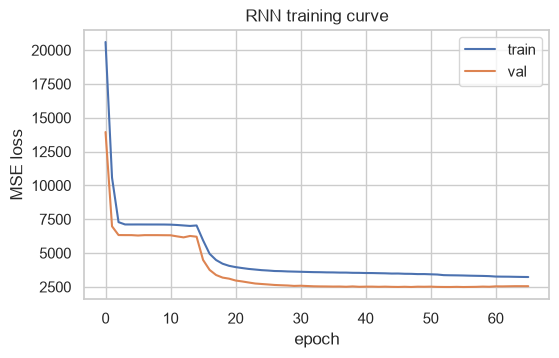

In [23]:
hist_rnn = rnn.fit(X_train_w, y_train_w, validation_data=(X_val_w, y_val_w),
                   epochs=EPOCHS, batch_size=BATCH, callbacks=make_callbacks(), verbose=2)
plot_history(hist_rnn, "RNN training curve")

Epoch 1/100
147/147 - 12s - 84ms/step - loss: 21900.6895 - mae: 121.5285 - val_loss: 16391.0605 - val_mae: 102.3347 - learning_rate: 0.0010
Epoch 2/100
147/147 - 6s - 42ms/step - loss: 12655.9756 - mae: 84.8158 - val_loss: 8110.7544 - val_mae: 69.8635 - learning_rate: 0.0010
Epoch 3/100
147/147 - 6s - 42ms/step - loss: 7747.9678 - mae: 67.9158 - val_loss: 6439.2993 - val_mae: 65.4128 - learning_rate: 0.0010
Epoch 4/100
147/147 - 6s - 42ms/step - loss: 7197.4233 - mae: 67.4620 - val_loss: 6397.9541 - val_mae: 65.7845 - learning_rate: 0.0010
Epoch 5/100
147/147 - 6s - 42ms/step - loss: 7184.6035 - mae: 67.6561 - val_loss: 6396.1816 - val_mae: 65.8105 - learning_rate: 0.0010
Epoch 6/100
147/147 - 6s - 42ms/step - loss: 7182.8755 - mae: 67.6617 - val_loss: 6394.9956 - val_mae: 65.8048 - learning_rate: 0.0010
Epoch 7/100
147/147 - 6s - 42ms/step - loss: 7181.9028 - mae: 67.6582 - val_loss: 6394.2090 - val_mae: 65.7999 - learning_rate: 0.0010
Epoch 8/100
147/147 - 6s - 42ms/step - loss: 7181

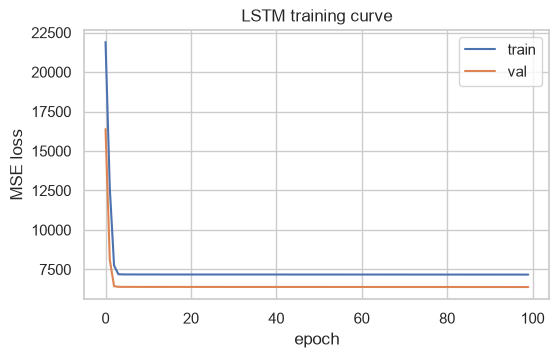

In [24]:
hist_lstm = lstm.fit(X_train_w, y_train_w, validation_data=(X_val_w, y_val_w),
                     epochs=EPOCHS, batch_size=BATCH, callbacks=make_callbacks(), verbose=2)
plot_history(hist_lstm, "LSTM training curve")

## 10. Evaluation and comparison

In [25]:
pred_rnn_w  = rnn.predict(X_test_w,  batch_size=1024, verbose=0)
pred_lstm_w = lstm.predict(X_test_w, batch_size=1024, verbose=0)

# ANN on the *same* cycles as the final step of every test window
ann_pred_last = ann.predict(X_test_w[:, -1, :], batch_size=1024, verbose=0).ravel()
y_last        = y_test_w[:, -1, 0]

rows = {
    "ANN  (all test cycles)":       m_ann_all,
    "ANN  (window final step)":     reg_metrics(y_last, ann_pred_last),
    "RNN  (all time steps)":        reg_metrics(y_test_w, pred_rnn_w),
    "RNN  (window final step)":     reg_metrics(y_last, pred_rnn_w[:, -1, 0]),
    "LSTM (all time steps)":        reg_metrics(y_test_w, pred_lstm_w),
    "LSTM (window final step)":     reg_metrics(y_last, pred_lstm_w[:, -1, 0]),
}
results = pd.DataFrame(rows).T.round(4)
results

,MAE,MSE,RMSE,R2
ANN (all test cycles),42.3133,3565.9277,59.7154,0.5801
ANN (window final step),38.2724,2839.0063,53.2823,0.6143
RNN (all time steps),42.3056,3465.7097,58.8703,0.5338
RNN (window final step),38.7365,2983.1958,54.6186,0.5947
LSTM (all time steps),69.8233,7518.0220,86.7065,-0.0112
LSTM (window final step),71.4340,7478.3013,86.4772,-0.0161


,MAE,MSE,RMSE,R2
ANN,38.2724,2839.0063,53.2823,0.6143
RNN,38.7365,2983.1958,54.6186,0.5947
LSTM,71.4340,7478.3013,86.4772,-0.0161


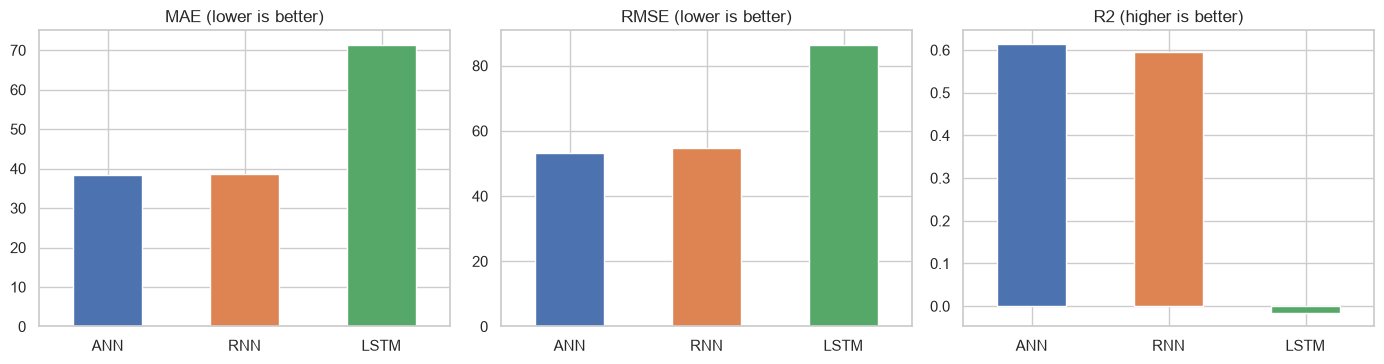

In [26]:
# Fair comparison table (final step only)
fair = results.loc[["ANN  (window final step)", "RNN  (window final step)", "LSTM (window final step)"]].copy()
fair.index = ["ANN", "RNN", "LSTM"]
display(fair)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, metric, better in zip(ax, ["MAE", "RMSE", "R2"], ["lower", "lower", "higher"]):
    fair[metric].plot.bar(ax=a, color=["#4c72b0", "#dd8452", "#55a868"], rot=0)
    a.set_title(f"{metric} ({better} is better)")
plt.tight_layout(); plt.show()

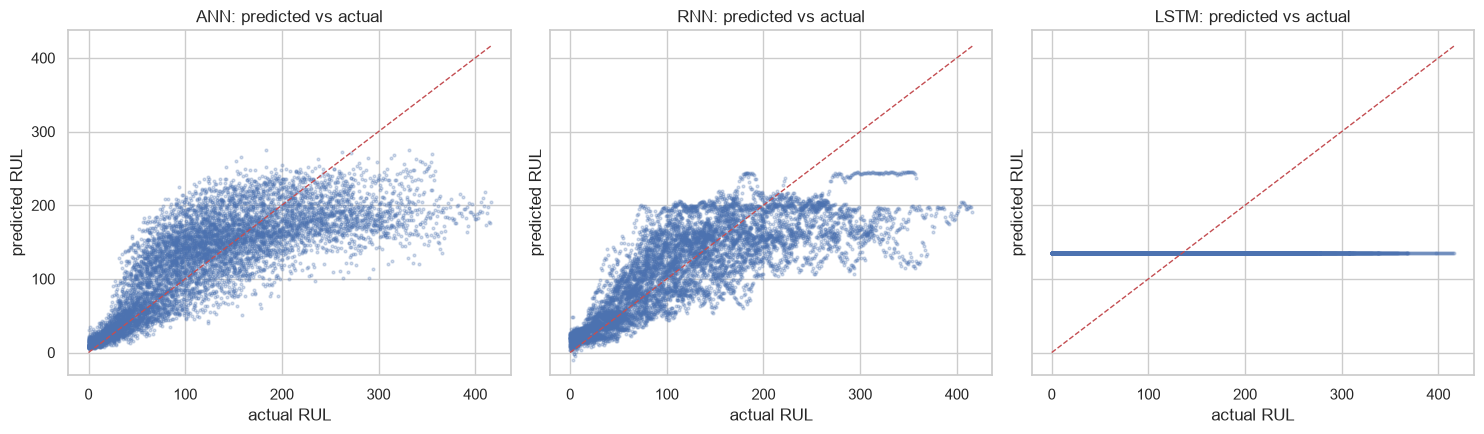

In [27]:
# Predicted vs actual (final step of each window)
preds = {"ANN": ann_pred_last, "RNN": pred_rnn_w[:, -1, 0], "LSTM": pred_lstm_w[:, -1, 0]}
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
lim = [0, max(y_last.max(), *(p.max() for p in preds.values()))]
for a, (name, p) in zip(ax, preds.items()):
    a.scatter(y_last, p, s=4, alpha=.25)
    a.plot(lim, lim, "r--", lw=1)
    a.set_title(f"{name}: predicted vs actual"); a.set_xlabel("actual RUL"); a.set_ylabel("predicted RUL")
plt.tight_layout(); plt.show()

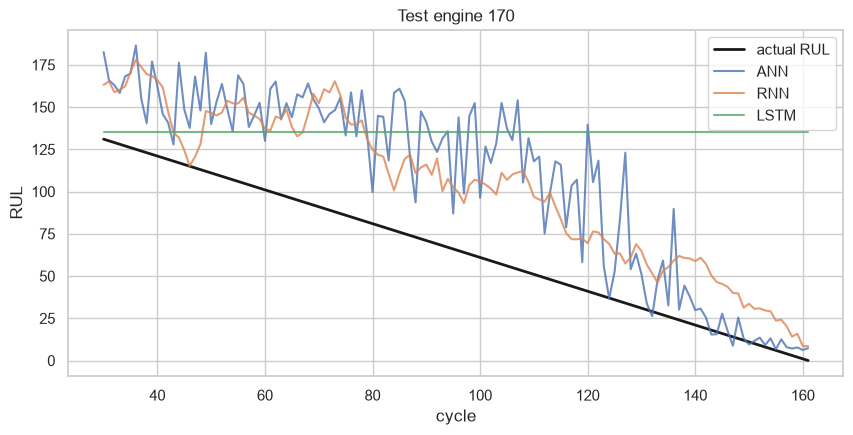

In [28]:
# Follow one test engine through its life: all three models vs the truth
eid = test_ids[0]
g = test_df[test_df[ID_COL] == eid]
Xe, ye, _ = make_windows(g)
t = g[TIME_COL].values[WINDOW - 1:]          # cycle index of each window's final step

plt.figure(figsize=(10, 4.5))
plt.plot(t, ye[:, -1, 0], "k-", lw=2, label="actual RUL")
plt.plot(t, ann.predict(Xe[:, -1, :], verbose=0).ravel(), label="ANN",  alpha=.8)
plt.plot(t, rnn.predict(Xe,  verbose=0)[:, -1, 0],         label="RNN",  alpha=.8)
plt.plot(t, lstm.predict(Xe, verbose=0)[:, -1, 0],         label="LSTM", alpha=.8)
plt.xlabel("cycle"); plt.ylabel("RUL"); plt.title(f"Test engine {eid}"); plt.legend(); plt.show()

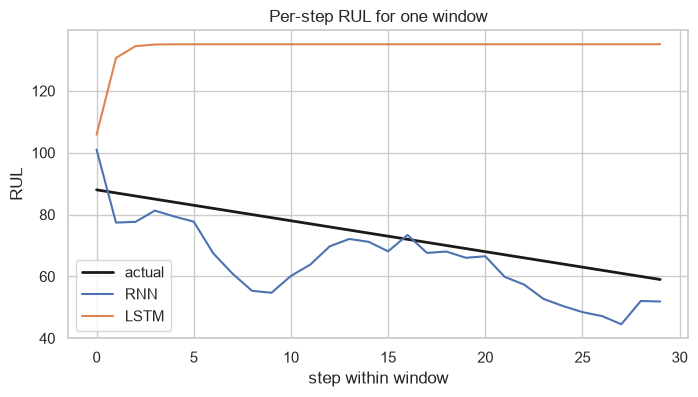

In [29]:
# The per-step RUL curve for ONE window (what the Streamlit app will display)
i = len(X_test_w) // 2
plt.figure(figsize=(8, 4))
plt.plot(range(WINDOW), y_test_w[i, :, 0], "k-", lw=2, label="actual")
plt.plot(range(WINDOW), pred_rnn_w[i, :, 0],  label="RNN")
plt.plot(range(WINDOW), pred_lstm_w[i, :, 0], label="LSTM")
plt.xlabel("step within window"); plt.ylabel("RUL"); plt.title("Per-step RUL for one window"); plt.legend(); plt.show()

## 11. Save models and artifacts

In [30]:
ann.save("../models/ann.keras")
rnn.save("../models/rnn.keras")
lstm.save("../models/lstm.keras")

results.to_csv("../artifacts/regression_results.csv")

# Sanity check: reload and confirm identical predictions
reloaded = keras.models.load_model("../models/lstm.keras")
assert np.allclose(reloaded.predict(X_test_w[:50], verbose=0), lstm.predict(X_test_w[:50], verbose=0), atol=1e-5)

print("Saved:", sorted(os.listdir("../models")), sorted(os.listdir("../artifacts")))

Saved: ['.gitkeep', 'ann.keras', 'lstm.keras', 'rnn.keras'] ['.gitkeep', 'config.json', 'regression_results.csv', 'scaler.pkl']
